# Intensity rescaling (BTXRD)
Normalizes every X-ray with intensity rescaling **at its full size** (2440 x 2440), and only then makes it 512 x 512 (the same way as notebook 07).
The new images are saved as PNG in **`BTXRD_rescaling_512.zip`**, in this folder. Inside the zip are the same `train`, `validation` and `test` folders, each with `normal` and `tumor`, as in `BTXRD_512.zip`. Every image stays in the same split as before.
The original data is only read, never changed.

Intensity rescaling stretches the gray values of each X-ray so they use the whole range: the darkest 1% of the X-ray becomes black (0), the brightest 1% becomes white (255), and everything in between is spread evenly. So a dim X-ray and a bright X-ray end up using the same range.

Why 1% and 99%, and not the darkest and the brightest pixel: in BTXRD the darkest pixel is always 0 (the black square), and in most images the brightest pixel is already 255 (a few very white pixels, for example letters like "R"). So stretching from the darkest to the brightest pixel would change almost nothing.

The 1% and 99% values are measured on the X-ray only (pixels brighter than `BLACK`), not on the black square. The black square stays black.

## Settings

In [1]:
import io
import json
import zipfile
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

DATA = Path("../../../../data/BTXRD no duplicates")    # the original full-size images without duplicates (only read)
ANNOTATIONS = DATA / "Annotations"                     # tumor outlines (only read)
OLD_ZIP = Path("../../../../data/BTXRD_512.zip")       # the baseline zip (only read, to check the split)
NAME = "BTXRD_rescaling_512"                           # the name of the new zip and of the folder inside it
NEW_ZIP = Path(NAME + ".zip")                          # the new zip is saved here, in this folder (Intensity rescaling)
SPLITS = ["train", "validation", "test"]
MALIGNANT = {"osteosarcoma", "other mt"}               # all other tumor types are benign

SIZE = (512, 512)    # the same size as the baseline
LOW_PERCENT = 1      # rescaling: the darkest 1% of the X-ray becomes black (0)
HIGH_PERCENT = 99    # rescaling: the brightest 1% of the X-ray becomes white (255)
BLACK = 15           # pixels at or below this are black background
RING = 10            # CII: width of the ring around the tumor, in pixels (on the 512 x 512 image)

## List the images
Every image in the `train`, `validation` and `test` folders, with its split, label (normal or tumor) and group (normal, benign or malignant).

In [2]:
def tumor_type(path):
    annotation = ANNOTATIONS / (path.stem + ".json")
    if not annotation.exists():
        return ""                                              # normal images have no annotation
    return json.loads(annotation.read_text())["shapes"][0]["label"]


records = []
for split in SPLITS:
    for path in sorted((DATA / split).glob("*/*.jp*g")):       # */ = normal or tumor, files end in .jpeg or .jpg
        kind = tumor_type(path)
        if kind == "":
            group = "normal"
        elif kind in MALIGNANT:
            group = "malignant"
        else:
            group = "benign"
        records.append({"image": path.stem, "split": split, "label": path.parent.name, "group": group, "path": path})

images = pd.DataFrame(records)
print(len(images), "images")
print(images.groupby(["split", "label"]).size())

3723 images
split       label 
test        normal     280
            tumor      279
train       normal    1306
            tumor     1300
validation  normal     280
            tumor      278
dtype: int64


## Check: the same split as `BTXRD_512.zip`
Every image must be in the same split (train, validation or test) and have the same label as in the baseline zip. If not, the notebook stops here.

In [3]:
with zipfile.ZipFile(OLD_ZIP) as old_zip:
    old_names = {name.removeprefix("BTXRD_512/").removesuffix(".png")   # for example train/normal/IMG001868
                 for name in old_zip.namelist() if name.endswith(".png")}
names = set(images["split"] + "/" + images["label"] + "/" + images["image"])

print("Images in BTXRD_512.zip:", len(old_names), "| images here:", len(names))
print("Same split and label for every image:", names == old_names)
assert names == old_names, "the split is not the same as in BTXRD_512.zip"

Images in BTXRD_512.zip: 3723 | images here: 3723
Same split and label for every image: True


## Functions
Load an image at full size, apply intensity rescaling, make it 512 x 512, and find the X-ray inside the black square.

In [4]:
def load(path):
    image = Image.open(path).convert("L")                      # gray, pixels 0 (black) to 255 (white)
    return np.array(image)                                     # full size: 2440 x 2440


def rescale(image):
    xray = image[image > BLACK]                                # the X-ray pixels, not the black square
    low, high = np.percentile(xray, [LOW_PERCENT, HIGH_PERCENT])   # the gray value of the darkest 1% and of the brightest 1%
    stretched = (image.astype(np.float64) - low) / (high - low) * 255   # low -> 0, high -> 255, the rest evenly in between
    return np.clip(stretched, 0, 255).round().astype(np.uint8) # below low -> 0 (so the black square stays black), above high -> 255


def shrink(image):
    image = Image.fromarray(image).resize(SIZE, Image.LANCZOS)  # 512 x 512, the same way as notebook 07
    return np.array(image)


def xray_box(image):
    rows = np.where((image > BLACK).any(axis=1))[0]            # rows with something brighter than black
    cols = np.where((image > BLACK).any(axis=0))[0]            # the same for columns
    return rows[0], rows[-1] + 1, cols[0], cols[-1] + 1        # top, bottom, left, right

## Before and after: 2 normal, 2 benign, 2 malignant
Both at 512 x 512, the size the models see. Before = the baseline image (the same as in `BTXRD_512.zip`).

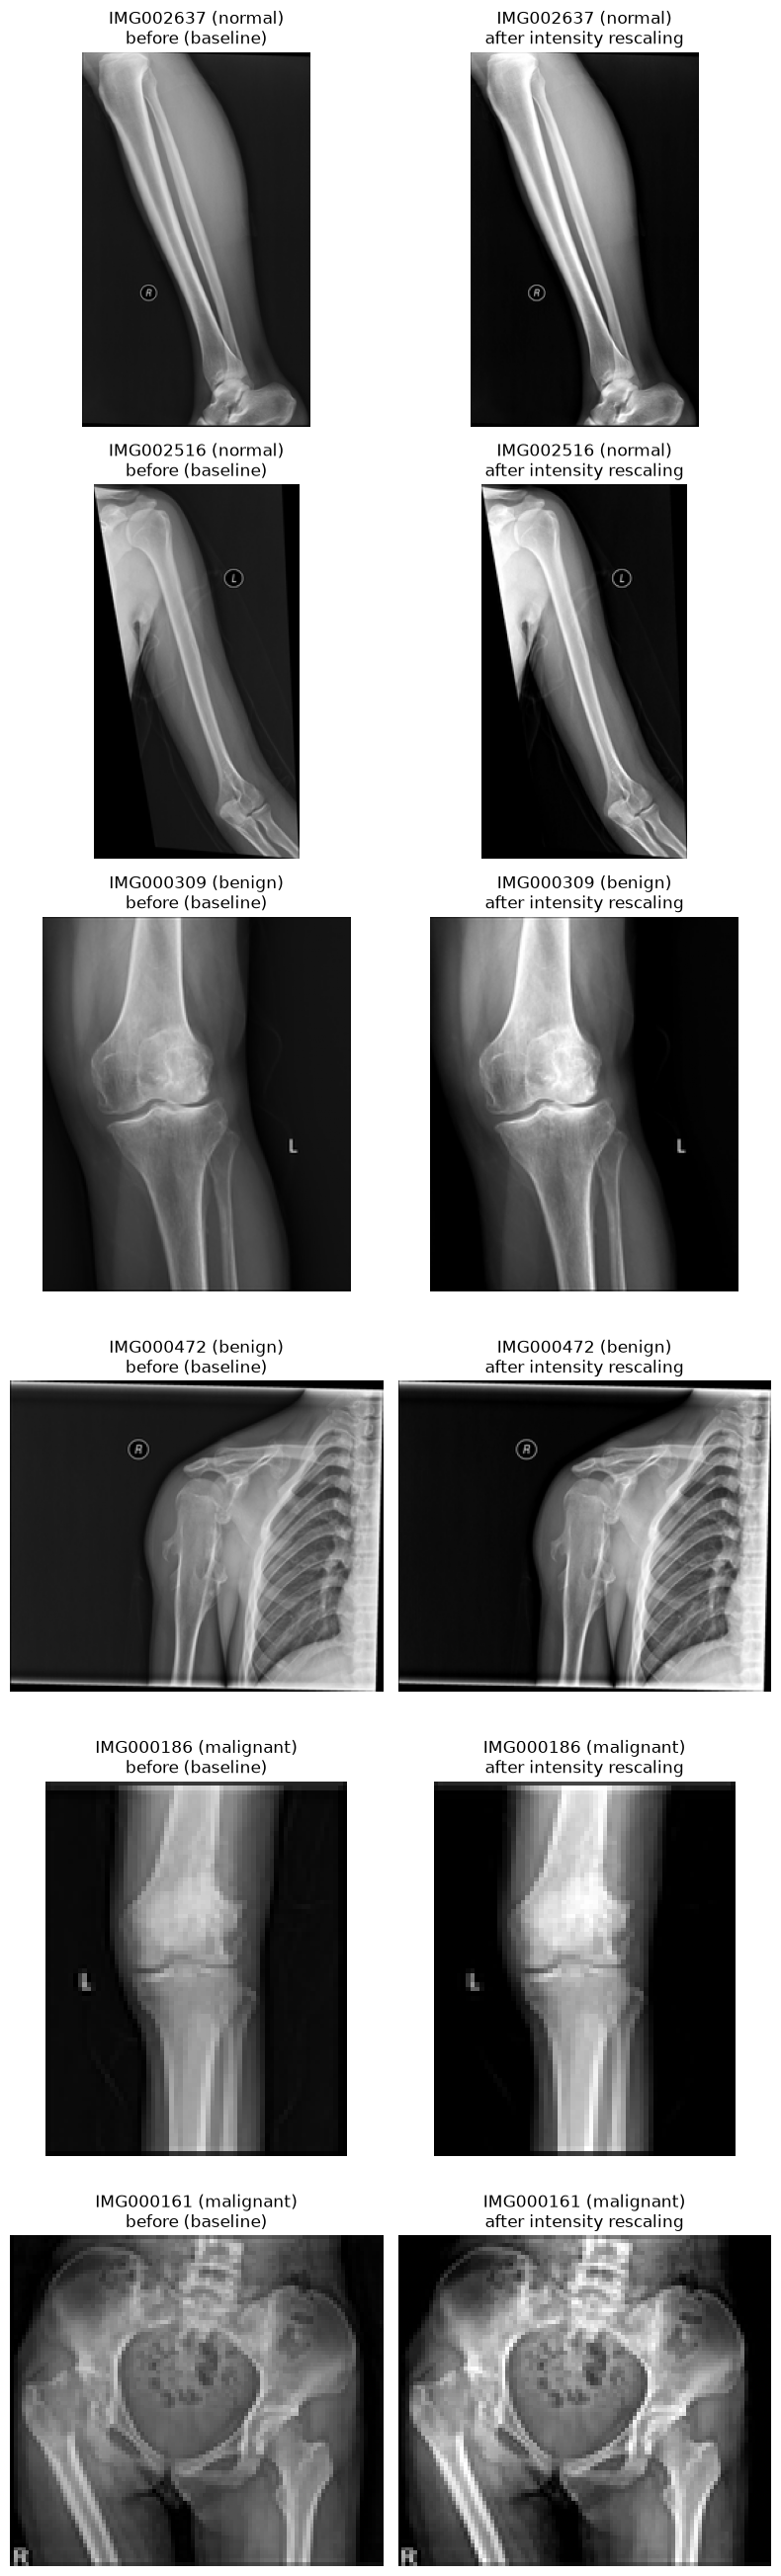

In [5]:
picks = pd.concat([images[images["group"] == group].sample(2, random_state=42)
                   for group in ["normal", "benign", "malignant"]])
titles = ["before (baseline)", "after intensity rescaling"]

fig, axes = plt.subplots(len(picks), 2, figsize=(8, 4.4 * len(picks)))
for row, (_, pick) in zip(axes, picks.iterrows()):
    raw = load(pick["path"])
    before = shrink(raw)                                       # the baseline image
    after = shrink(rescale(raw))                               # intensity rescaling on the full image, then 512 x 512
    top, bottom, left, right = xray_box(before)                # cut away the black square, so the bone is big enough to see
    for ax, picture, title in zip(row, [before, after], titles):
        ax.imshow(picture[top:bottom, left:right], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{pick['image']} ({pick['group']})\n{title}")
        ax.axis("off")

plt.tight_layout()
plt.show()

## Measuring functions
Both images are compared at 512 x 512: the baseline image (before) and the new image (after).
- PSNR and SSIM: how much the image changed (higher = less change). Measured on the X-ray only, not the black square.
- CII: how much more the tumor stands out from the ring around it. Above 1 = it stands out more.

In [6]:
def tumor_mask(name):
    annotation = json.loads((ANNOTATIONS / (name + ".json")).read_text())
    scale = SIZE[0] / annotation["imageWidth"]                 # the outline was drawn on the 2440 x 2440 image
    mask = np.zeros((SIZE[1], SIZE[0]), dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape["shape_type"] == "polygon":                   # the outline (the rectangles are only boxes)
            points = np.round(np.array(shape["points"]) * scale).astype(np.int32)
            cv2.fillPoly(mask, [points], 1)
    return mask == 1                                           # True inside the tumor


def ring_around(tumor, before):
    kernel = np.ones((2 * RING + 1, 2 * RING + 1), dtype=np.uint8)
    bigger = cv2.dilate(tumor.astype(np.uint8), kernel) == 1   # the tumor made RING pixels bigger
    return bigger & ~tumor & (before > BLACK)                  # the ring: not the tumor, not the black background


def contrast(image, tumor, ring):
    t = image[tumor].mean()                                    # tumor brightness
    r = image[ring].mean()                                     # ring brightness
    return abs(t - r) / (t + r)                                # abs: a tumor can be darker or brighter than the bone


def cii(before, after, tumor, ring):
    if tumor.sum() == 0 or ring.sum() == 0:
        return np.nan                                          # cannot be measured
    contrast_before = contrast(before, tumor, ring)
    if contrast_before == 0:
        return np.nan                                          # cannot divide by 0
    return contrast(after, tumor, ring) / contrast_before


def psnr_ssim(before, after):
    top, bottom, left, right = xray_box(before)                # the X-ray only
    a, b = before[top:bottom, left:right], after[top:bottom, left:right]
    return peak_signal_noise_ratio(a, b, data_range=255), structural_similarity(a, b, data_range=255)

## Make every image, save it in the zip, and measure it
For every image: intensity rescaling on the full image, then 512 x 512, then saved as PNG in the zip (`BTXRD_rescaling_512/split/label/name.png`).
Then PSNR, SSIM and CII against the baseline image. CII is only for tumor images. This takes some minutes.

In [7]:
rows = []
with zipfile.ZipFile(NEW_ZIP, "w") as new_zip:                 # "w": makes a new zip (an old one with the same name is replaced)
    for n, (_, item) in enumerate(images.iterrows(), start=1):
        raw = load(item["path"])
        before = shrink(raw)                                   # the baseline image
        after = shrink(rescale(raw))                           # intensity rescaling on the full image, then 512 x 512

        png = io.BytesIO()                                     # make the PNG file in memory ...
        Image.fromarray(after).save(png, format="PNG")
        new_zip.writestr(f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png", png.getvalue())   # ... and put it in the zip

        psnr, ssim = psnr_ssim(before, after)
        row = {"image": item["image"], "label": item["label"], "PSNR": psnr, "SSIM": ssim, "CII": np.nan}
        if item["label"] == "tumor":
            tumor = tumor_mask(item["image"])
            row["CII"] = cii(before, after, tumor, ring_around(tumor, before))
        rows.append(row)

        if n % 500 == 0:
            print(n, "of", len(images), "done")

scores = pd.DataFrame(rows)
print(len(images), "images saved in", NEW_ZIP)

500 of 3723 done
1000 of 3723 done
1500 of 3723 done
2000 of 3723 done
2500 of 3723 done
3000 of 3723 done
3500 of 3723 done
3723 images saved in BTXRD_rescaling_512.zip


## Check the new zip
Counts the images in each folder, checks that all are 512 x 512 gray images, and that every image is in the same split and label as in `BTXRD_512.zip`.

In [8]:
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    files = [name for name in new_zip.namelist() if name.endswith(".png")]
    sizes, modes = Counter(), Counter()
    for name in files:
        image = Image.open(new_zip.open(name))
        sizes[image.size] += 1
        modes[image.mode] += 1                                 # L = gray

for folder, count in sorted(Counter(name.rsplit("/", 1)[0] for name in files).items()):
    print(folder, count)
print("Sizes:", dict(sizes), "| modes:", dict(modes))
new_names = {name.removeprefix(NAME + "/").removesuffix(".png") for name in files}
print("Same images, split and label as BTXRD_512.zip:", new_names == old_names)
print("Zip size:", round(NEW_ZIP.stat().st_size / 1e6), "MB")

BTXRD_rescaling_512/test/normal 280
BTXRD_rescaling_512/test/tumor 279
BTXRD_rescaling_512/train/normal 1306
BTXRD_rescaling_512/train/tumor 1300
BTXRD_rescaling_512/validation/normal 280
BTXRD_rescaling_512/validation/tumor 278
Sizes: {(512, 512): 3723} | modes: {'L': 3723}
Same images, split and label as BTXRD_512.zip: True
Zip size: 72 MB


## Results
The middle value (median) of each score: the image after intensity rescaling compared with the baseline image. CII only counts the tumor images.

In [9]:
scores[["PSNR", "SSIM", "CII"]].median().round(3)

PSNR    21.989
SSIM     0.779
CII      1.219
dtype: float64